In [1]:
!pip install fasttext

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/73.4 kB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 2.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-2.13.6-py3-none-any.whl.metadata (9.5 kB)
Using cached pybind11-2.13.6-py3-none-any.whl (243 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp311-cp311-linux_x86_64.whl size=4313473 sha256=bed00bfeda00f8907e7225c355e11424e71df5a05a12ae592e77510ea82899d3
  Stored in directory: /root/.cache/pip/wheels/65/4f/35/5057db0249224e9ab55a513fa6b79451473ceb7713017823c3
Successfully built fasttext


In [6]:
import numpy as np
import pandas as pd
import os
import h5py
import json
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# LNN
import torch
import torch.nn as nn
from LiqudNet.liquidnet.main import LiquidNet
from torch.utils.data import random_split, DataLoader

#KAN
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, TensorDataset
from tqdm.auto import tqdm
import numpy as np

import torch
import torch.nn.functional as F
import math

from torchsummary import summary

# Preprocessing
import re
import nltk
import spacy
import fasttext
import numpy as np
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

ImportError: DLL load failed while importing pypocketfft: %1 is not a valid Win32 application.

In [10]:
# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to C:\Users\Muhammad
[nltk_data]     Darab\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Muhammad
[nltk_data]     Darab\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\Muhammad
[nltk_data]     Darab\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\Muhammad
[nltk_data]     Darab\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Muhammad
[nltk_data]     Darab\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## Dataset Loading and Splitting

In [ ]:
# Already created so no need to run this

hdf5_path = "../Datasets/Final/Character_Embeddings.hdf5"

# Get sorted batch files
batch_files = sorted(os.listdir('../Datasets/Final/Character_Embeddings/'), key = lambda x: int(x.split('_')[-1].split('.npy')[0]))

# Determine total number of samples
total_samples = 85878

# Open an HDF5 file for writing
with h5py.File(hdf5_path, "w") as f:
    # Define dataset shape (total_samples, 2000, 128), stored as float16
    dset = f.create_dataset("Character_Embeddings", shape = (total_samples, 2000, 128), dtype = np.float16)

    # Write each batch into the dataset
    index = 0
    for file in batch_files:
        batch_path = os.path.join('../Datasets/Final/Character_Embeddings/', file)
        batch_data = np.load(batch_path).astype(np.float16)  # Convert to float16 to save memory
        batch_size = batch_data.shape[0]

        dset[index : index + batch_size] = batch_data  # Store batch in HDF5
        index += batch_size

        del batch_data

print("HDF5 file created successfully!")

In [11]:
class FakeNewsDataset(Dataset):
    def __init__(self, word_embeddings_file, positional_embeddings_file, character_embeddings_hdf5, labels_file = None):
        self.word_embeddings = np.load(word_embeddings_file)
        self.positional_embeddings = np.load(positional_embeddings_file)

        # Open HDF5 file in read mode
        self.h5_file = h5py.File(character_embeddings_hdf5, "r")
        self.character_embeddings = self.h5_file["Character_Embeddings"]

        # Load labels if available
        if labels_file:
            self.labels = pd.read_csv(labels_file, header = None)[0].values
        else:
            self.labels = None

    def __len__(self):
        return len(self.word_embeddings)  # Assuming word embeddings match character embeddings

    def __getitem__(self, idx):
        word_embedding = torch.tensor(self.word_embeddings[idx], dtype = torch.float32)
        positional_embedding = torch.tensor(self.positional_embeddings[idx], dtype = torch.float32)
        character_embedding = torch.tensor(self.character_embeddings[idx], dtype = torch.float32)  # Efficiently read from HDF5

        if self.labels is not None:
            label = torch.tensor(self.labels[idx], dtype = torch.long)
            return word_embedding, positional_embedding, character_embedding, label
        else:
            return word_embedding, positional_embedding, character_embedding

In [12]:
# Define dataset sizes
def split_dataset(dataset, train_ratio = 0.8, val_ratio = 0.1):
    """
    Split the dataset into train, validation, and test subsets.
    :param dataset: The complete dataset.
    :param train_ratio: Proportion of the data to be used for training.
    :param val_ratio: Proportion of the data to be used for validation.
    :return: Train, validation, and test subsets.
    """
    total_size = len(dataset)
    train_size = int(train_ratio * total_size)
    val_size = int(val_ratio * total_size)
    test_size = total_size - train_size - val_size

    return random_split(dataset, [train_size, val_size, test_size])

In [24]:
# Path to the embeddings and labels
word_embeddings_file = '../Datasets/Final/Fixed_Embeddings_Sequence.npy'
positional_embeddings_file = '../Datasets/Final/Positional_Encodings.npy'
character_embeddings_hdf5 = '../Datasets/Final/Character_Embeddings.hdf5'
labels_file = '../Datasets/Final/Encoded_Labels.csv'  # CSV file with a 'type' column for real/fake labels
# Initialize the dataset with both embeddings and labels
dataset = FakeNewsDataset(word_embeddings_file, positional_embeddings_file, character_embeddings_hdf5, labels_file)

In [ ]:
dataloader = DataLoader(dataset, batch_size = 32, shuffle = True, num_workers = 0)

## **LQN**: Imported

## KAN

In [13]:
class KANLinear(torch.nn.Module):
    def __init__(
        self,
        in_features,
        out_features,
        grid_size = 5,
        spline_order = 3,
        scale_noise = 0.1,
        scale_base = 1.0,
        scale_spline = 1.0,
        enable_standalone_scale_spline = True,
        base_activation = torch.nn.SiLU,
        grid_eps = 0.02,
        grid_range = [-1, 1],
    ):
        super(KANLinear, self).__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.grid_size = grid_size
        self.spline_order = spline_order

        h = (grid_range[1] - grid_range[0]) / grid_size
        grid = (
            (
                torch.arange(-spline_order, grid_size + spline_order + 1) * h
                + grid_range[0]
            )
            .expand(in_features, -1)
            .contiguous()
        )
        self.register_buffer("grid", grid)

        self.base_weight = torch.nn.Parameter(torch.Tensor(out_features, in_features))
        self.spline_weight = torch.nn.Parameter(
            torch.Tensor(out_features, in_features, grid_size + spline_order)
        )
        if enable_standalone_scale_spline:
            self.spline_scaler = torch.nn.Parameter(
                torch.Tensor(out_features, in_features)
            )

        self.scale_noise = scale_noise
        self.scale_base = scale_base
        self.scale_spline = scale_spline
        self.enable_standalone_scale_spline = enable_standalone_scale_spline
        self.base_activation = base_activation()
        self.grid_eps = grid_eps

        self.reset_parameters()

    def reset_parameters(self):
        torch.nn.init.kaiming_uniform_(self.base_weight, a = math.sqrt(5) * self.scale_base)
        with torch.no_grad():
            noise = (
                (
                    torch.rand(self.grid_size + 1, self.in_features, self.out_features)
                    - 1 / 2
                )
                * self.scale_noise
                / self.grid_size
            )
            self.spline_weight.data.copy_(
                (self.scale_spline if not self.enable_standalone_scale_spline else 1.0)
                * self.curve2coeff(
                    self.grid.T[self.spline_order : -self.spline_order],
                    noise,
                )
            )
            if self.enable_standalone_scale_spline:
                # torch.nn.init.constant_(self.spline_scaler, self.scale_spline)
                torch.nn.init.kaiming_uniform_(self.spline_scaler, a = math.sqrt(5) * self.scale_spline)

    def b_splines(self, x: torch.Tensor):
        """
        Compute the B-spline bases for the given input tensor.

        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, in_features).

        Returns:
            torch.Tensor: B-spline bases tensor of shape (batch_size, in_features, grid_size + spline_order).
        """
        assert x.dim() == 2 and x.size(1) == self.in_features

        grid: torch.Tensor = (
            self.grid
        )  # (in_features, grid_size + 2 * spline_order + 1)
        x = x.unsqueeze(-1)
        bases = ((x >= grid[:, :-1]) & (x < grid[:, 1:])).to(x.dtype)
        for k in range(1, self.spline_order + 1):
            bases = (
                (x - grid[:, : -(k + 1)])
                / (grid[:, k:-1] - grid[:, : -(k + 1)])
                * bases[:, :, :-1]
            ) + (
                (grid[:, k + 1 :] - x)
                / (grid[:, k + 1 :] - grid[:, 1:(-k)])
                * bases[:, :, 1:]
            )

        assert bases.size() == (
            x.size(0),
            self.in_features,
            self.grid_size + self.spline_order,
        )
        return bases.contiguous()

    def curve2coeff(self, x: torch.Tensor, y: torch.Tensor):
        """
        Compute the coefficients of the curve that interpolates the given points.

        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, in_features).
            y (torch.Tensor): Output tensor of shape (batch_size, in_features, out_features).

        Returns:
            torch.Tensor: Coefficients tensor of shape (out_features, in_features, grid_size + spline_order).
        """
        assert x.dim() == 2 and x.size(1) == self.in_features
        assert y.size() == (x.size(0), self.in_features, self.out_features)

        A = self.b_splines(x).transpose(
            0, 1
        )  # (in_features, batch_size, grid_size + spline_order)
        B = y.transpose(0, 1)  # (in_features, batch_size, out_features)
        solution = torch.linalg.lstsq(
            A, B
        ).solution  # (in_features, grid_size + spline_order, out_features)
        result = solution.permute(
            2, 0, 1
        )  # (out_features, in_features, grid_size + spline_order)

        assert result.size() == (
            self.out_features,
            self.in_features,
            self.grid_size + self.spline_order,
        )
        return result.contiguous()

    @property
    def scaled_spline_weight(self):
        return self.spline_weight * (
            self.spline_scaler.unsqueeze(-1)
            if self.enable_standalone_scale_spline
            else 1.0
        )

    def forward(self, x: torch.Tensor):
        assert x.size(-1) == self.in_features
        original_shape = x.shape
        x = x.reshape(-1, self.in_features)

        base_output = F.linear(self.base_activation(x), self.base_weight)
        spline_output = F.linear(
            self.b_splines(x).view(x.size(0), -1),
            self.scaled_spline_weight.view(self.out_features, -1),
        )
        output = base_output + spline_output

        output = output.reshape(*original_shape[:-1], self.out_features)
        return output

    @torch.no_grad()
    def update_grid(self, x: torch.Tensor, margin = 0.01):
        assert x.dim() == 2 and x.size(1) == self.in_features
        batch = x.size(0)

        splines = self.b_splines(x)  # (batch, in, coeff)
        splines = splines.permute(1, 0, 2)  # (in, batch, coeff)
        orig_coeff = self.scaled_spline_weight  # (out, in, coeff)
        orig_coeff = orig_coeff.permute(1, 2, 0)  # (in, coeff, out)
        unreduced_spline_output = torch.bmm(splines, orig_coeff)  # (in, batch, out)
        unreduced_spline_output = unreduced_spline_output.permute(
            1, 0, 2
        )  # (batch, in, out)

        # sort each channel individually to collect data distribution
        x_sorted = torch.sort(x, dim = 0)[0]
        grid_adaptive = x_sorted[
            torch.linspace(
                0, batch - 1, self.grid_size + 1, dtype=torch.int64, device = x.device
            )
        ]

        uniform_step = (x_sorted[-1] - x_sorted[0] + 2 * margin) / self.grid_size
        grid_uniform = (
            torch.arange(
                self.grid_size + 1, dtype = torch.float32, device=x.device
            ).unsqueeze(1)
            * uniform_step
            + x_sorted[0]
            - margin
        )

        grid = self.grid_eps * grid_uniform + (1 - self.grid_eps) * grid_adaptive
        grid = torch.concatenate(
            [
                grid[:1]
                - uniform_step
                * torch.arange(self.spline_order, 0, -1, device = x.device).unsqueeze(1),
                grid,
                grid[-1:]
                + uniform_step
                * torch.arange(1, self.spline_order + 1, device = x.device).unsqueeze(1),
            ],
            dim = 0,
        )

        self.grid.copy_(grid.T)
        self.spline_weight.data.copy_(self.curve2coeff(x, unreduced_spline_output))

    def regularization_loss(self, regularize_activation=1.0, regularize_entropy=1.0):
        """
        Compute the regularization loss.

        This is a dumb simulation of the original L1 regularization as stated in the
        paper, since the original one requires computing absolutes and entropy from the
        expanded (batch, in_features, out_features) intermediate tensor, which is hidden
        behind the F.linear function if we want an memory efficient implementation.

        The L1 regularization is now computed as mean absolute value of the spline
        weights. The authors implementation also includes this term in addition to the
        sample-based regularization.
        """
        l1_fake = self.spline_weight.abs().mean(-1)
        regularization_loss_activation = l1_fake.sum()
        p = l1_fake / regularization_loss_activation
        regularization_loss_entropy = -torch.sum(p * p.log())
        return (
            regularize_activation * regularization_loss_activation
            + regularize_entropy * regularization_loss_entropy
        )

In [14]:
class KAN(torch.nn.Module):
    def __init__(
        self,
        layers_hidden,
        grid_size = 5,
        spline_order = 3,
        scale_noise = 0.1,
        scale_base = 1.0,
        scale_spline = 1.0,
        base_activation = torch.nn.SiLU,
        grid_eps = 0.02,
        grid_range = [-1, 1],
    ):
        super(KAN, self).__init__()
        self.grid_size = grid_size
        self.spline_order = spline_order

        self.layers = torch.nn.ModuleList()
        for in_features, out_features in zip(layers_hidden, layers_hidden[1:]):
            self.layers.append(
                KANLinear(
                    in_features,
                    out_features,
                    grid_size = grid_size,
                    spline_order = spline_order,
                    scale_noise = scale_noise,
                    scale_base = scale_base,
                    scale_spline = scale_spline,
                    base_activation = base_activation,
                    grid_eps = grid_eps,
                    grid_range = grid_range,
                )
            )

    def forward(self, x: torch.Tensor, update_grid = False):
        for layer in self.layers:
            if update_grid:
                layer.update_grid(x)
            x = layer(x)
        return x

    def regularization_loss(self, regularize_activation = 1.0, regularize_entropy = 1.0):
        return sum(
            layer.regularization_loss(regularize_activation, regularize_entropy)
            for layer in self.layers
        )

## Combined Model

In [15]:
# class FakeNewsDetectionModel(nn.Module):
#     def __init__(self, input_size, hidden_units, output_size):
#         super(FakeNewsDetectionModel, self).__init__()
#         self.multihead_attn = nn.MultiheadAttention(input_size, 4, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
#         self.gru_1 = nn.GRU(input_size, hidden_units // 4, num_layers = 1, bidirectional = True, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
#         self.gru_2 = nn.GRU(hidden_units // 2, hidden_units // 16, num_layers = 1, bidirectional = False, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
#         self.ifc = nn.Linear(120 * hidden_units // 16, hidden_units * 4).to("cuda" if torch.cuda.is_available() else "cpu")
#         self.o = nn.Linear(hidden_units // 2, output_size).to("cuda" if torch.cuda.is_available() else "cpu")
#         self.ltc_cell = LiquidNet(hidden_units * 2).to("cuda" if torch.cuda.is_available() else "cpu")  # LiquidNet cell
#         self.kan_1 = KANLinear(hidden_units * 2, hidden_units, base_activation = nn.SiLU).to("cuda" if torch.cuda.is_available() else "cpu") # KAN
#         self.kan_2 = KANLinear(hidden_units, hidden_units // 2, base_activation = nn.SiLU).to("cuda" if torch.cuda.is_available() else "cpu")

#     def forward(self, x):
#         # LiquidNet requires an initial hidden state
#         batch_size = x.size(0)
#         hidden_state = torch.zeros(batch_size, self.ltc_cell._num_units).to(x.device)

#         # Initial Pass
#         outputs, _ = self.multihead_attn(x, x, x)
#         outputs, _ = self.gru_1(outputs)
#         outputs, _ = self.gru_2(outputs)

#         # Pass through Initial Fully Connected Layer
#         outputs = self.ifc(outputs.reshape(batch_size, 120 * hidden_units // 16))

#         # Pass input through the LiquidNet cell
#         outputs, _ = self.ltc_cell(outputs, hidden_state)

#         # Pass LiquidNet output to KAN
#         outputs = self.kan_1(outputs)
#         outputs = self.kan_2(outputs)

#         # Final pass
#         outputs = self.o(outputs)

#         return outputs

## Reducing Character Embeddings

In [16]:
class CharacterEmbeddingsReductionModel(nn.Module):
    def __init__(self, input_size = 128, hidden_units = 256, output_size = 1, num_heads = 4):
        super(CharacterEmbeddingsReductionModel, self).__init__()

        self.mish = nn.Mish()

        # CNN Block for Feature Extraction
        self.conv1 = nn.Conv1d(in_channels = input_size, out_channels = hidden_units // 2, kernel_size = 3, padding = 1).to("cuda" if torch.cuda.is_available() else "cpu")
        self.conv2 = nn.Conv1d(in_channels = hidden_units // 2, out_channels = hidden_units, kernel_size = 3, padding = 1).to("cuda" if torch.cuda.is_available() else "cpu")
        self.batch_norm = nn.BatchNorm1d(hidden_units).to("cuda" if torch.cuda.is_available() else "cpu")

        # GRU Layers for Temporal Encoding
        self.gru_1 = nn.GRU(hidden_units, hidden_units // 4, num_layers = 1, bidirectional = True, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
        self.norm_1 = nn.LayerNorm(hidden_units // 2).to("cuda" if torch.cuda.is_available() else "cpu")
        self.gru_2 = nn.GRU(hidden_units // 2, hidden_units // 64, num_layers = 1, bidirectional = False, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
        self.norm_2 = nn.LayerNorm(hidden_units // 64).to("cuda" if torch.cuda.is_available() else "cpu")
        self.gru_3 = nn.GRU(hidden_units // 4, hidden_units // 16, num_layers = 1, bidirectional = True, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
        self.norm_3 = nn.LayerNorm(hidden_units // 8).to("cuda" if torch.cuda.is_available() else "cpu")
        self.gru_4 = nn.GRU(hidden_units // 8, hidden_units // 64, num_layers = 1, bidirectional = False, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
        self.norm_4 = nn.LayerNorm(hidden_units // 64).to("cuda" if torch.cuda.is_available() else "cpu")

        # Self-Attention Layer
        self.attention = nn.MultiheadAttention(embed_dim = hidden_units // 64, num_heads = num_heads, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")

        # Final Layers
        self.o_1 = nn.Linear(125 * hidden_units // 64, hidden_units).to("cuda" if torch.cuda.is_available() else "cpu")
        self.o_2 = nn.Linear(hidden_units, hidden_units // 2).to("cuda" if torch.cuda.is_available() else "cpu")
        self.o_3 = nn.Linear(hidden_units // 2, hidden_units // 4).to("cuda" if torch.cuda.is_available() else "cpu")
        self.o_4 = nn.Linear(hidden_units // 4, hidden_units // 8).to("cuda" if torch.cuda.is_available() else "cpu")
        self.o_5 = nn.Linear(hidden_units // 8, output_size).to("cuda" if torch.cuda.is_available() else "cpu")

        # Dropout for Regularization
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        batch_size = x.shape[0]

        # CNN Feature Extraction
        x = x.permute(0, 2, 1)  # Change to (batch, channels, seq_len)
        x = self.mish(self.conv1(x))
        x = self.mish(self.conv2(x))
        x = self.batch_norm(x)
        x = x.permute(0, 2, 1)  # Change back to (batch, seq_len, channels)

        # GRU Layers
        outputs, _ = self.gru_1(x)
        outputs = self.norm_1(outputs)
        outputs, _ = self.gru_2(outputs)
        outputs = self.norm_2(outputs)
        reduced_character_embeddings = outputs.reshape(batch_size, 125, -1)
        outputs, _ = self.gru_3(outputs.reshape(batch_size, 125, -1))
        outputs = self.norm_3(outputs)
        outputs, _ = self.gru_4(outputs)
        outputs = self.norm_4(outputs)

        # Self-Attention
        outputs, _ = self.attention(outputs, outputs, outputs)

        # Fully Connected Layers
        outputs = self.mish(self.o_1(outputs.reshape(batch_size, -1)))
        outputs = self.dropout(outputs)
        outputs = self.mish(self.o_2(outputs))
        outputs = self.dropout(outputs)
        outputs = self.mish(self.o_3(outputs))
        outputs = self.mish(self.o_4(outputs))
        outputs = self.o_5(outputs)

        return outputs, reduced_character_embeddings

In [17]:
def train_validate(model, train_loader, num_epochs = 10, learning_rate = 0.001):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate, betas = (0.9, 0.999))
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience = 5, factor = 0.9)

    for epoch in range(num_epochs):
        # Training Phase
        model.train()
        train_loss = 0.0
        y_true_train = []
        y_pred_train = []
        character_embeddings_reduced = []

        for _, _, char_embeddings, labels in tqdm(train_loader):
            char_embeddings, labels = char_embeddings.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs, character_embedding_reduced = model(char_embeddings.float())  # Outputs should have shape [batch_size, num_classes]
            loss = criterion(outputs, labels.unsqueeze(1).float())  # CrossEntropyLoss expects raw logits and class indices
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            # Get predicted class indices
            outputs = nn.Sigmoid()(outputs)
            y_true_train.extend(labels.cpu().numpy())
            y_pred_train.extend((outputs > 0.5).detach().cpu().numpy())

            character_embeddings_reduced.append(character_embedding_reduced.detach().cpu().numpy())

        # Calculate accuracy using sklearn
        train_accuracy = accuracy_score(y_true_train, y_pred_train) * 100
        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Learning Rate: {optimizer.param_groups[-1]['lr']:.5f}")

        scheduler.step(train_loss)

        if train_accuracy >= 80:
            print('80% training accuracy reached')
            break

    return character_embeddings_reduced

In [ ]:
# Initialize the model
input_size = 128  # Input size matches your embeddings
hidden_units = 256  # Number of units for LiquidNet
output_size = 1  # Binary classification (real/fake)
character_reduction_model = CharacterEmbeddingsReductionModel(input_size, hidden_units, output_size)

In [ ]:
# If trained already, no need to run the model again, just load it

In [ ]:
# Provide the model, input size (excluding batch size), and device
summary(character_reduction_model, input_size = (2000, input_size), device = "cuda" if torch.cuda.is_available() else "cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv1d-1            [-1, 128, 2000]          49,280
              Mish-2            [-1, 128, 2000]               0
            Conv1d-3            [-1, 256, 2000]          98,560
              Mish-4            [-1, 256, 2000]               0
       BatchNorm1d-5            [-1, 256, 2000]             512
               GRU-6  [[-1, 2000, 128], [-1, 2, 64]]               0
         LayerNorm-7            [-1, 2000, 128]             256
               GRU-8  [[-1, 2000, 4], [-1, 2, 4]]               0
         LayerNorm-9              [-1, 2000, 4]               8
              GRU-10  [[-1, 125, 32], [-1, 2, 16]]               0
        LayerNorm-11              [-1, 125, 32]              64
              GRU-12  [[-1, 125, 4], [-1, 2, 4]]               0
        LayerNorm-13               [-1, 125, 4]               8
MultiheadAttention-14  [[-1,

In [ ]:
# Train and validate
character_embeddings_reduced = train_validate(character_reduction_model, dataloader, num_epochs = 25, learning_rate = 0.0001)

  0%|          | 0/2684 [00:00<?, ?it/s]

Epoch 1/25, Train Loss: 1209.1703, Train Accuracy: 72.56%, Learning Rate: 0.00010


  0%|          | 0/2684 [00:00<?, ?it/s]

Epoch 2/25, Train Loss: 1048.4041, Train Accuracy: 77.79%, Learning Rate: 0.00010


  0%|          | 0/2684 [00:00<?, ?it/s]

Epoch 3/25, Train Loss: 995.6226, Train Accuracy: 80.42%, Learning Rate: 0.00010
80% training accuracy reached


In [ ]:
# If already saved, ignore this and run the next cell

torch.save(character_reduction_model.state_dict(), 'Saved/Model_Character_Reduction_125_64.pth')

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
character_reduction_model = character_reduction_model.to(device)
character_reduction_model.load_state_dict(torch.load('Saved/Model_Character_Reduction_125_64.pth', map_location = device))

<All keys matched successfully>

## Update Training and Validation Dataloaders

In [ ]:
# If already saved, ignore this and the next cell and run the third

character_embeddings_reduced_numpy = np.vstack(character_embeddings_reduced)

In [ ]:
np.save('../Datasets/Final/Character_Embeddings_Reduced_Numpy.npy', character_embeddings_reduced_numpy)

In [25]:
character_embeddings_reduced_numpy = np.load('../Datasets/Final/Character_Embeddings_Reduced_Numpy.npy')

In [26]:
dataset.character_embeddings = character_embeddings_reduced_numpy

In [27]:
train_dataset, val_dataset, test_dataset = split_dataset(dataset, train_ratio = 0.8, val_ratio = 0.1)

# Create DataLoaders for each subset
train_loader = DataLoader(train_dataset, batch_size = 32, shuffle = True, num_workers = 0)
val_loader = DataLoader(val_dataset, batch_size = 32, shuffle = False, num_workers = 0)
test_loader = DataLoader(test_dataset, batch_size = 32, shuffle = False, num_workers = 0)

# Example: Iterate through train DataLoader
for word_embeddings, positional_embeddings, character_embeddings, labels in train_loader:
    print("Train batch:", word_embeddings.shape, positional_embeddings.shape, character_embeddings.shape, labels.shape)
    break

# Example: Iterate through validation DataLoader
for word_embeddings, positional_embeddings, character_embeddings, labels in val_loader:
    print("Validation batch:", word_embeddings.shape, positional_embeddings.shape, character_embeddings.shape, labels.shape)
    break

# Example: Iterate through test DataLoader
for word_embeddings, positional_embeddings, character_embeddings, labels in test_loader:
    print("Test batch:", word_embeddings.shape, positional_embeddings.shape, character_embeddings.shape, labels.shape)
    break

Train batch: torch.Size([32, 120, 128]) torch.Size([32, 120, 128]) torch.Size([32, 125, 64]) torch.Size([32])
Validation batch: torch.Size([32, 120, 128]) torch.Size([32, 120, 128]) torch.Size([32, 125, 64]) torch.Size([32])
Test batch: torch.Size([32, 120, 128]) torch.Size([32, 120, 128]) torch.Size([32, 125, 64]) torch.Size([32])


## Normal Train

In [28]:
class FakeNewsDetectionModel(nn.Module):
    def __init__(self, input_size, hidden_units, output_size):
        super(FakeNewsDetectionModel, self).__init__()
        # Word Embeddings Block + Positional Embeddings Block
        self.multihead_attn_wepe = nn.MultiheadAttention(input_size, 4, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
        self.gru_1_wepe = nn.GRU(input_size, hidden_units // 4, num_layers = 1, bidirectional = True, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
        self.gru_2_wepe = nn.GRU(hidden_units // 2, hidden_units // 16, num_layers = 1, bidirectional = False, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")

        # Character Embeddings Block
        self.conv1_ce = nn.Conv1d(hidden_units, hidden_units // 2, kernel_size = 3, stride = 1, padding = 1).to("cuda" if torch.cuda.is_available() else "cpu")
        self.conv2_ce = nn.Conv1d(hidden_units // 2, hidden_units // 4, kernel_size = 6, stride = 1, padding = 0).to("cuda" if torch.cuda.is_available() else "cpu")
        self.gru_1_ce = nn.GRU(hidden_units // 4, hidden_units // 16, num_layers = 1, bidirectional = True, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")
        self.gru_2_ce = nn.GRU(hidden_units // 8 , hidden_units // 16, num_layers = 1, bidirectional = False, batch_first = True).to("cuda" if torch.cuda.is_available() else "cpu")

        # Output and Shared Block
        self.fc = nn.Linear(120 * 2 * hidden_units // 16, hidden_units * 4).to("cuda" if torch.cuda.is_available() else "cpu")
        self.ltc_cell = LiquidNet(hidden_units * 2).to("cuda" if torch.cuda.is_available() else "cpu")  # LiquidNet cell
        self.kan_1 = KANLinear(hidden_units * 2, hidden_units, base_activation = nn.SiLU).to("cuda" if torch.cuda.is_available() else "cpu") # KAN
        self.kan_2 = KANLinear(hidden_units, hidden_units // 2, base_activation = nn.SiLU).to("cuda" if torch.cuda.is_available() else "cpu")
        self.o = nn.Linear(hidden_units // 2, output_size).to("cuda" if torch.cuda.is_available() else "cpu")

    def forward(self, x, y, z):
        # LiquidNet requires an initial hidden state
        batch_size = x.size(0)
        hidden_state = torch.zeros(batch_size, self.ltc_cell._num_units).to(x.device)

        # Word Embeddings Pass + Positional Embeddings Pass
        outputs = torch.add(x, y)
        outputs, _ = self.multihead_attn_wepe(outputs, outputs, outputs)
        outputs, _ = self.gru_1_wepe(outputs)
        outputs_wepe, _ = self.gru_2_wepe(outputs)

        # Character Embeddings Pass
        outputs = self.conv1_ce(z.reshape(batch_size, 64, 125))
        outputs = self.conv2_ce(outputs)
        outputs, _ = self.gru_1_ce(outputs.reshape(batch_size, 120, 16))
        outputs_ce, _ = self.gru_2_ce(outputs)

        # Pass through Output and Shared Block
        outputs = torch.cat((outputs_wepe, outputs_ce), dim = 2)
        outputs = self.fc(outputs.reshape(batch_size, 120 * hidden_units // 8))
        outputs, _ = self.ltc_cell(outputs, hidden_state)
        outputs = self.kan_1(outputs)
        outputs = self.kan_2(outputs)
        outputs = self.o(outputs)

        return outputs

## Training and Validation Helper Functions

In [29]:
def train_validate(model, train_loader, val_loader, num_epochs = 10, learning_rate = 0.001):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate, betas = (0.9, 0.999))
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience = 5, factor = 0.9)

    for epoch in range(num_epochs):
        # Training Phase
        model.train()
        train_loss = 0.0
        y_true_train = []
        y_pred_train = []

        for word_embeddings, pos_embeddings, char_embeddings, labels in tqdm(train_loader):
            word_embeddings, pos_embeddings, char_embeddings, labels = word_embeddings.to(device), pos_embeddings.to(device), char_embeddings.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(word_embeddings.float(), pos_embeddings.float(), char_embeddings.float())  # Outputs should have shape [batch_size, num_classes]
            loss = criterion(outputs, labels.unsqueeze(1).float())  # CrossEntropyLoss expects raw logits and class indices
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            # Get predicted class indices
            outputs = nn.Sigmoid()(outputs)
            y_true_train.extend(labels.cpu().numpy())
            y_pred_train.extend((outputs > 0.5).detach().cpu().numpy())

        # Calculate accuracy using sklearn
        train_accuracy = accuracy_score(y_true_train, y_pred_train) * 100
        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Learning Rate: {optimizer.param_groups[-1]['lr']:.5f}")

        # Validation Phase
        val_loss = 0.0
        y_true_val = []
        y_pred_val = []

        with torch.no_grad():
            for word_embeddings, pos_embeddings, char_embeddings, labels in val_loader:
                word_embeddings, pos_embeddings, char_embeddings, labels = word_embeddings.to(device), pos_embeddings.to(device), char_embeddings.to(device), labels.to(device)

                outputs = model(word_embeddings.float(), pos_embeddings.float(), char_embeddings.float())
                loss = criterion(outputs, labels.unsqueeze(1).float())
                val_loss += loss.item()

                # Get predicted class indices
                outputs = nn.Sigmoid()(outputs)
                y_true_val.extend(labels.cpu().numpy())
                y_pred_val.extend((outputs > 0.5).detach().cpu().numpy())

        scheduler.step(val_loss)

        # Calculate validation accuracy using sklearn
        val_accuracy = accuracy_score(y_true_val, y_pred_val) * 100
        print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.2f}%")

In [30]:
def test(model, test_loader):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    test_loss = 0.0
    criterion = nn.BCEWithLogitsLoss()
    y_true_test = []
    y_pred_test = []

    with torch.no_grad():
        for word_embeddings, pos_embeddings, char_embeddings, labels in test_loader:
            word_embeddings, pos_embeddings, char_embeddings, labels = word_embeddings.to(device), pos_embeddings.to(device), char_embeddings.to(device), labels.to(device)

            outputs = model(word_embeddings.float(), pos_embeddings.float(), char_embeddings.float())
            loss = criterion(outputs, labels.unsqueeze(1).float())
            test_loss += loss.item()

            # Get predicted class indices
            outputs = nn.Sigmoid()(outputs)
            y_true_test.extend(labels.cpu().numpy())
            y_pred_test.extend((outputs > 0.5).detach().cpu().numpy())

    test_accuracy = accuracy_score(y_true_test, y_pred_test) * 100
    print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

In [33]:
# Initialize the model
input_size = 128  # Input size matches your embeddings
hidden_units = 64  # Number of units for LiquidNet
output_size = 1  # Binary classification (real/fake)
model = FakeNewsDetectionModel(input_size, hidden_units, output_size)

In [ ]:
# Provide the model, input size (excluding batch size), and device
summary(model, input_size = [(120, input_size), (120, input_size), (125, hidden_units)], device = "cuda" if torch.cuda.is_available() else "cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
MultiheadAttention-1  [[-1, 120, 128], [-1, 120, 120]]               0
               GRU-2  [[-1, 120, 32], [-1, 2, 16]]               0
               GRU-3  [[-1, 120, 4], [-1, 2, 4]]               0
            Conv1d-4              [-1, 32, 125]           6,176
            Conv1d-5              [-1, 16, 120]           3,088
               GRU-6  [[-1, 120, 8], [-1, 2, 4]]               0
               GRU-7  [[-1, 120, 4], [-1, 2, 4]]               0
            Linear-8                  [-1, 256]         246,016
         LiquidNet-9     [[-1, 128], [-1, 128]]               0
             SiLU-10                  [-1, 128]               0
        KANLinear-11                   [-1, 64]               0
             SiLU-12                   [-1, 64]               0
        KANLinear-13                   [-1, 32]               0
           Linear-14      

In [ ]:
# Train and validate
train_validate(model, train_loader, val_loader, num_epochs = 25, learning_rate = 0.0001)

  0%|          | 0/2147 [00:00<?, ?it/s]

Epoch 1/25, Train Loss: 1075.7417, Train Accuracy: 70.19%, Learning Rate: 0.00010
Validation Loss: 95.6305, Validation Accuracy: 80.67%


  0%|          | 0/2147 [00:00<?, ?it/s]

Epoch 2/25, Train Loss: 750.8828, Train Accuracy: 81.28%, Learning Rate: 0.00010
Validation Loss: 98.0985, Validation Accuracy: 80.55%


  0%|          | 0/2147 [00:00<?, ?it/s]

...

Epoch 23/25, Train Loss: 634.6366, Train Accuracy: 84.45%, Learning Rate: 0.00010
Validation Loss: 83.2851, Validation Accuracy: 83.70%


  0%|          | 0/2147 [00:00<?, ?it/s]

Epoch 24/25, Train Loss: 632.9131, Train Accuracy: 84.41%, Learning Rate: 0.00010
Validation Loss: 82.1633, Validation Accuracy: 84.08%


  0%|          | 0/2147 [00:00<?, ?it/s]

Epoch 25/25, Train Loss: 630.1282, Train Accuracy: 84.52%, Learning Rate: 0.00010
Validation Loss: 84.2481, Validation Accuracy: 83.99%


In [ ]:
train_validate(model, train_loader, val_loader, num_epochs = 25, learning_rate = 0.0001)

  0%|          | 0/2147 [00:00<?, ?it/s]

Epoch 1/25, Train Loss: 659.9030, Train Accuracy: 83.83%, Learning Rate: 0.00010
Validation Loss: 79.7287, Validation Accuracy: 83.87%


  0%|          | 0/2147 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# No need to run, aleady trained and saved

np.save('./Train_Accuracies.npy', np.array(train_accuracies))
np.save('./Validation_Accuracies.npy', np.array(val_accuracies))

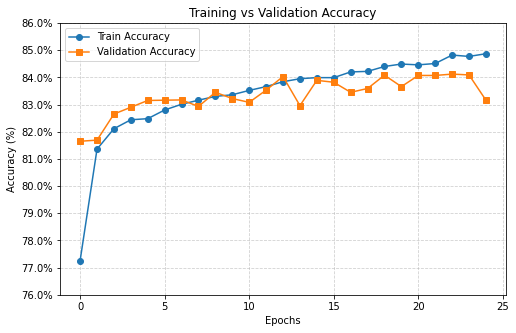

In [21]:
# Load accuracy values
train_accuracies = np.load('./Train_Accuracies.npy').astype(np.float32)
val_accuracies = np.load('./Validation_Accuracies.npy').astype(np.float32)

# Plot
plt.figure(figsize = (8, 5))
plt.plot(train_accuracies, label = "Train Accuracy", marker = 'o')
plt.plot(val_accuracies, label = "Validation Accuracy", marker = 's')

# Labels and title
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")

# Set appropriate y-axis limits based on data range
min_acc = min(np.min(train_accuracies), np.min(val_accuracies)) - 1
max_acc = max(np.max(train_accuracies), np.max(val_accuracies)) + 1
plt.ylim(min_acc, max_acc)  # Dynamically adjust y-axis limits

# Adjust y-ticks dynamically
plt.yticks(np.arange(round(min_acc), round(max_acc) + 1, 1))  # Adjust interval as needed
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1f}%'))  # Show 1 decimal place

plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.6)
plt.show()

In [ ]:
# Don't run after training

torch.save(model, 'Saved/Model_Combined_Word_Positional_Character.pth')

In [34]:
model = torch.load('Saved/Model_Combined_Word_Positional_Character.pth', weights_only = False)

In [35]:
# Test the model
test(model, test_loader)

Test Loss: 78.6793, Test Accuracy: 84.65%


## Pipeline

In [50]:
# Load Character Embeddings Reduction Model

input_size = 128  # Input size matches your embeddings
hidden_units_character = 256  # Number of units for LiquidNet
output_size = 1  # Binary classification (real/fake)
character_reduction_model = CharacterEmbeddingsReductionModel(input_size, hidden_units_character, output_size)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
character_reduction_model = character_reduction_model.to(device)
character_reduction_model.load_state_dict(torch.load('Saved/Model_Character_Reduction_125_64.pth', map_location = device))

# Load Fake News Classification Model

fake_new_model = torch.load('Saved/Model_Combined_Word_Positional_Character.pth', weights_only = False)

In [51]:
# Load SpaCy model
nlp = spacy.load('en_core_web_sm')

# Load stopwords
stop_words = set(stopwords.words('english'))

# Load FastText Model
model = fasttext.load_model('unsupervised_fasttext_model.bin')

# Set Parameters
MAX_WORDS = 120
MAX_CHARS = 2000
EMBEDDING_DIM = 128

In [52]:
# Generate Positional Encoding
positional_encoding = np.zeros((MAX_WORDS, EMBEDDING_DIM))
position = np.arange(MAX_WORDS)[:, np.newaxis]
div_term = np.exp(np.arange(0, EMBEDDING_DIM, 2) * -(np.log(10000.0) / EMBEDDING_DIM))
positional_encoding[:, 0::2] = np.sin(position * div_term)
positional_encoding[:, 1::2] = np.cos(position * div_term)
positional_encoding = positional_encoding.astype(np.float16)

In [88]:
def preprocess_and_generate_embedding(text):
    """
    Preprocesses text and generates word, positional, and character embeddings.
    Returns:
        word_embedding (np.array): (MAX_WORDS, EMBEDDING_DIM)
        positional_embedding (np.array): (MAX_WORDS, EMBEDDING_DIM)
        char_embedding (np.array): (MAX_CHARS, EMBEDDING_DIM)
    """
    # 1️⃣ Text Standardization
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\b\d+\b', '', text)
    text = re.sub(r'http\S+|www\S+|@\S+', '', text)

    # 2️⃣ Tokenization
    tokens = word_tokenize(text)

    # 3️⃣ Stopword Removal
    tokens = [word for word in tokens if word not in stop_words]

    # 4️⃣ Lemmatization
    doc = nlp(' '.join(tokens))
    words = [token.lemma_ for token in doc]

    # 5️⃣ Generate Word Embeddings
    words = words[:MAX_WORDS] if len(words) > MAX_WORDS else words + [''] * (MAX_WORDS - len(words))
    vectors = [model.get_word_vector(word) if word in model.words else np.zeros(EMBEDDING_DIM) for word in words]
    word_embedding = np.vstack(vectors)

    # 6️⃣ Generate Positional Encoding
    positional_embedding = positional_encoding[:len(words)]

    # 7️⃣ Generate Character Embeddings
    chars = list(text)[:MAX_CHARS] if len(text) > MAX_CHARS else list(text) + [' '] * (MAX_CHARS - len(text))
    char_vectors = [model.get_word_vector(char) if char in model.words else np.zeros(EMBEDDING_DIM) for char in chars]
    char_embedding = np.vstack(char_vectors)

    return word_embedding.astype(np.float16), positional_embedding.astype(np.float16), char_embedding.astype(np.float16)


In [101]:
def pipeline(news_article, character_model, news_model, device = 'cuda'):

    # Preprocessing Start

    word_embeddings, positional_embeddings, character_embeddings = preprocess_and_generate_embedding(news_article)

    # Preprocessing End

    word_embeddings = torch.Tensor(word_embeddings).to(device)
    positional_embeddings = torch.Tensor(positional_embeddings).to(device)
    character_embeddings = torch.Tensor(character_embeddings).to(device)
    
    word_embeddings = word_embeddings[np.newaxis, :, :]
    positional_embeddings = positional_embeddings[np.newaxis, :, :]
    character_embeddings = character_embeddings[np.newaxis, :, :]

    _, character_embeddings_reduced = character_model(character_embeddings.float())
    output = news_model(word_embeddings.float(),  positional_embeddings.float(), character_embeddings_reduced.float())
    output = nn.Sigmoid()(output)
    label = (output > 0.5).detach().cpu().numpy()
    accuracy = output.detach().cpu().numpy().flatten()[0] * 100
    if label == 0:
        accuracy = 100 - accuracy
    accuracy = "{:.2f}".format(int(accuracy * 100) / 100)
    if label == 1:
        decision = 'News unverified, likely fake' + ' with accuracy ' + str(accuracy) + '%'
    else:
        decision = 'news verified, likely real' + ' with accuracy ' + str(accuracy) + '%'

    # Explainability Start
    explainability = 'Explanation'
    # Explainability End

    return decision, explainability

In [106]:
article_real = 'Solidarity with working people in Ukraine and their fight against Russia’s invasion never meant support for the Zelensky government, the US government, NATO, or the designs of rival imperial powers, but lack of international solidarity has left Ukrainians in an impossible situation.'
decision_real, explainability_real = pipeline(article_real, character_reduction_model, fake_new_model)

In [107]:
article_fake = 'A law enforcement sniper assigned to former President Donald Trump’s rally Saturday in Butler, Penn., says the head of the Secret Service ordered him not to shoot the suspect accused of attempting to assassinate Trump.'
decision_fake, explainability_fake = pipeline(article_fake, character_reduction_model, fake_new_model)

In [108]:
decision_real, explainability_real

('News verified, likely real with accuracy 76.43%', 'Explanation')

In [109]:
decision_fake, explainability_fake

('news unverified, likely fake with accuracy 33.08%', 'Explanation')